# Physical Model of the Quantum Sensor

The code implements a **quantum sensor based on a single qubit**, inspired by the formalism of C.L. Degen, F. Reinhard, and P. Cappellaro in their article *Quantum sensing*.

## Qubit as a Phase Sensor

A two-level qubit is described by the state:

$$
|\psi\rangle = \alpha |0\rangle + \beta |1\rangle, \quad |\alpha|^2 + |\beta|^2 = 1.
$$

The qubit is exposed to an oscillating electromagnetic field at frequency $\omega$.  
We assume a regime of **weak field**, so the applied electromagnetic oscillation is neither resonant nor strong enough to induce transitions between the qubit energy levels. Instead, its interaction with the qubit is well described as a **modulation of the energy spacing** of the levels $\vert 0\rangle$ and $\vert 1\rangle$, i.e., an **energy shift** between the two levels.  
This shift does not exchange population between the states, but produces an accumulation of **relative phase** proportional to time.  

> **Important note:** here we assume **an idealized and unrealistic condition**, in which the qubit and the electromagnetic wave are perfectly synchronized, so that the accumulated phase can be modeled directly as linear in time. In reality, measuring the frequency \(\omega\) of the field would require control sequences like modulated Ramsey or spin-echo to filter the relevant component.

In first approximation (weak field), the accumulated phase is therefore:

$$
\phi(t)=\omega\,t,
$$

where $\omega$ is the frequency of the applied oscillation and $\phi(t)$ is the relative phase between $|0\rangle$ and $|1\rangle$, which can be measured via an interferometric protocol like Ramsey. 

## Quantum Control Sequence (Ramsey)

The circuit implements a **Ramsey-type interference**:

1. **Initial Hadamard** to create superposition:

$$
|0\rangle \xrightarrow{H} \frac{|0\rangle + |1\rangle}{\sqrt{2}}
$$

2. **Rotation around the Z axis** to accumulate phase:

$$
R_z(\phi) = \begin{pmatrix} e^{-i\phi/2} & 0 \\ 0 & e^{i\phi/2} \end{pmatrix}
$$

3. **Second Hadamard** to convert the phase into measurement probability:

$$
P_0(t) = |\langle 0 | H R_z(\phi(t)) H |0\rangle|^2 = \cos^2\left(\frac{\phi(t)}{2}\right)
$$

The function `measure_probability(t)` calculates this probability via quantum simulation.

## Phase Extraction

From the probability $P_0(t)$ we recover the accumulated phase:

$$
\phi_\text{measured}(t) = 2 \arccos \sqrt{P_0(t)}
$$

Comparing $\phi_\text{measured}(t)$ with the true phase $\phi(t)=\omega t$, the qubit acts as a **quantum phase sensor**.

## Ramsey Circuit

```python
from qiskit import QuantumCircuit
qc = QuantumCircuit(1,1)
qc.h(0)
qc.rz(0.5,0)  # example phase
qc.h(0)
qc.measure(0,0)
qc.draw('mpl')

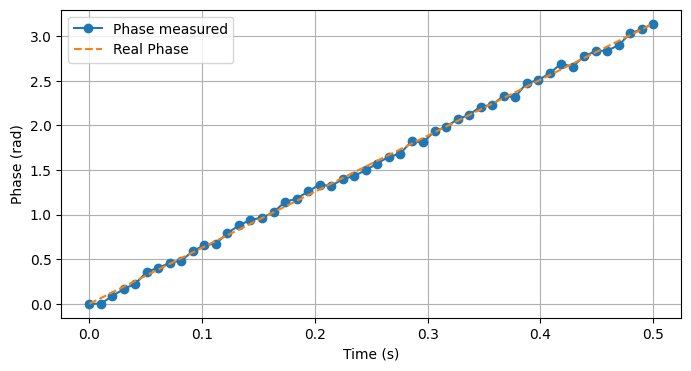

In [1]:
from qiskit import QuantumCircuit, transpile
from qiskit_aer import AerSimulator
import numpy as np
from matplotlib import pyplot as plt

# --- Eletromagnetic wave parameters ---
omega = 2 * np.pi * 1   # frequence (Hz)
timesteps = np.linspace(0, 0.5, 50)  # time in seconds
shots = 1024

# Backend simulator
simulator = AerSimulator()

# Function that measures the probability of |0>
def measure_probability(t):
    phi = omega * t
    qc = QuantumCircuit(1,1)
    qc.h(0)
    qc.rz(phi,0)
    qc.h(0)
    qc.measure(0,0)
    qc = transpile(qc, simulator)
    result = simulator.run(qc, shots=shots).result()
    counts = result.get_counts()
    p0 = counts.get('0',0)/shots
    return p0

# Calculate the probabilities for each time
probabilities = np.array([measure_probability(t) for t in timesteps])

# Estimation of the measured phase

phi_measured =2 * np.arccos(np.sqrt(probabilities))

# Plot  
plt.figure(figsize=(8,4))
plt.plot(timesteps, phi_measured, 'o-', label='Phase measured')
plt.plot(timesteps, omega*timesteps, '--', label='Real Phase')
plt.xlabel("Time (s)")
plt.ylabel("Phase (rad)")
plt.legend()
plt.grid(True)
plt.show()